In [ ]:
import numpy as np

from numba import njit

from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.preprocessing import StandardScaler

import plotly.graph_objects as go
from plotly.subplots import make_subplots

import fastplotlib as fpl

import optuna
from optuna.visualization import plot_pareto_front
from optuna.trial import TrialState

from dysts.maps import Henon

import time

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),Apple M4,IntegratedGPU,Metal,


To silence this warning, use a fully namespaced name.


# Init

## Init Reservoir

In [2]:
steps = 20000

tau_steps = 1

transient_steps_chaos = int(steps * 0.1)
transient_steps_reservoir = int(steps * 0.1)

total_steps = steps + transient_steps_chaos + transient_steps_reservoir + tau_steps
total_steps_after_chaos = steps + transient_steps_reservoir + tau_steps

test_size = 0.2
test_steps = int(steps * test_size)

t = np.arange(0, total_steps)

In [3]:
henon_model = Henon()
henon_dataset = henon_model.make_trajectory(total_steps)
henon_dataset = henon_dataset[transient_steps_chaos:]

In [4]:
henon_scaler = StandardScaler()
henon_train_scaled = henon_scaler.fit_transform(henon_dataset[:-test_steps])
henon_test_scaled = henon_scaler.transform(henon_dataset[-test_steps:])
henon_scaled = np.concatenate((henon_train_scaled, henon_test_scaled), axis=0)

## Init Funcs

In [5]:
def scatter_plot(data_list, names=["Test", "Pred"], colors=["white", "magenta"]):
    fig = go.Figure()

    for i, data in enumerate(data_list):
        if data.ndim == 1:
            fig.add_trace(
                go.Scatter(
                    x=np.arange(len(data)),
                    y=data,
                    mode="markers",
                    name=names[i],
                    marker=dict(color=colors[i % len(colors)], size=1),
                )
            )
        elif data.ndim == 2:
            fig.add_trace(
                go.Scatter(
                    x=data[:, 0],
                    y=data[:, 1],
                    mode="markers",
                    name=names[i],
                    marker=dict(color=colors[i % len(colors)], size=1),
                )
            )
        else:
            fig.add_trace(
                go.Scatter3d(
                    x=data[:, 0],
                    y=data[:, 1],
                    z=data[:, 2],
                    mode="markers",
                    name=names[i],
                    marker=dict(color=colors[i % len(colors)], size=1),
                )
            )

    fig.update_layout(template="plotly_dark", title="Attractor Comparison")

    return fig

In [6]:
def r_2_plots_grid(actual_list, predicted_list, titles):
    actual_list = actual_list.reshape(-1, 1) if actual_list.ndim == 1 else actual_list
    predicted_list = predicted_list.reshape(-1, 1) if predicted_list.ndim == 1 else predicted_list

    fig = make_subplots(rows=1, cols=actual_list.shape[1], subplot_titles=titles)

    for i in range(actual_list.shape[1]):
        actual = actual_list[:, i]
        predicted = predicted_list[:, i]
        r_2 = r2_score(actual, predicted)
        col = i + 1

        fig.add_trace(
            go.Scatter(
                x=actual,
                y=predicted,
                mode="markers",
                name="Data",
                marker=dict(color="rgba(50, 50, 200, 0.5)", size=5),
            ),
            row=1,
            col=col,
        )

        min_val, max_val = min(actual.min(), predicted.min()), max(
            actual.max(), predicted.max()
        )
        fig.add_trace(
            go.Scatter(
                x=[min_val, max_val],
                y=[min_val, max_val],
                mode="lines",
                name="Ideal",
                line=dict(color="firebrick", dash="dash"),
            ),
            row=1,
            col=col,
        )

        fig.update_xaxes(title_text="Actual", row=1, col=col)
        fig.update_yaxes(title_text=f"Predicted (R²: {r_2:.4f})", row=1, col=col)

    fig.update_layout(showlegend=False, height=500, width=1000)
    return fig

In [7]:
def plot_grid(nodes_pos):
    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=nodes_pos[:, 0],
            y=nodes_pos[:, 1],
            mode="markers",
            marker=dict(size=8, color="teal"),
        )
    )

    fig.update_layout(
        title="Hexagonal Lattice Distribution",
        xaxis=dict(title="X Position", scaleanchor="y", scaleratio=1),
        yaxis=dict(title="Y Position"),
        plot_bgcolor="white",
        width=700,
        height=700,
    )

    return fig


In [8]:
def weight_plot(weights, dims):
    dim_names = ["x", "y", "z"][:dims]
    num_features_per_type = len(weights) // 2
    num_nodes = num_features_per_type // dims

    labels = []
    for n in range(num_nodes):
        for d in range(dims):
            labels.append(f"Node {n + 1} {dim_names[d]} Pos")
            labels.append(f"Node {n + 1} {dim_names[d]} Vel")

    weights_flat = weights.flatten()
    pos_part = weights_flat[:num_features_per_type]
    vel_part = weights_flat[num_features_per_type:]

    combined_weights = np.empty_like(weights_flat)
    combined_weights[0::2] = pos_part
    combined_weights[1::2] = vel_part

    fig = go.Figure(
        data=[
            go.Bar(
                x=labels,
                y=combined_weights,
                marker_color=np.where(combined_weights >= 0, "royalblue", "firebrick"),
            )
        ]
    )

    fig.update_layout(
        title="Reservoir Node Contribution (Feature Weights)",
        xaxis_title="Node State & Dimension",
        yaxis_title="Weight Value",
        template="plotly_white",
    )

    return fig

In [9]:
def spring_animation(
    disp,
    nodes_pos,
    connections_list,
    size=10,
    external=False,
    is_3d=False,
    frames_moved=5,
    max_frames=2000,
    animate=True,
    highlighted_nodes=None,
    wall_nodes=None,
    vel=None,
    steps_jump=1,
):
    disp = disp[::steps_jump]

    steps = disp.shape[0]
    num_nodes = nodes_pos.shape[0]
    dims = nodes_pos.shape[1]

    fig = (
        fpl.Figure(canvas="glfw" if external else "jupyter")
        if not is_3d
        else fpl.Figure(
            cameras="3d",
            controller_types="orbit",
            canvas="glfw" if external else "jupyter",
        )
    )

    node_colors = np.array(["magenta"] * num_nodes)
    if highlighted_nodes is not None:
        node_colors[highlighted_nodes] = "lime"
    if wall_nodes is not None and wall_nodes[0] != -1:
        node_colors[wall_nodes] = "blue"

    disp_reshaped = disp.reshape(steps, num_nodes, dims)
    disp_3d = np.pad(disp_reshaped, ((0, 0), (0, 0), (0, 3 - dims)), mode="constant")
    nodes_pos_3d = np.pad(nodes_pos, ((0, 0), (0, 3 - dims)), mode="constant")
    coords = nodes_pos_3d + disp_3d[0]

    dots = fig[0, 0].add_scatter(
        data=coords.astype(np.float32), sizes=size, colors=node_colors
    )
    lines = [
        fig[0, 0].add_line(
            data=np.vstack([coords[int(row[0])], coords[int(row[1])]]).astype(
                np.float32
            ),
            thickness=2,
            colors="cyan",
        )
        for row in connections_list
    ]

    if vel is not None:
        vel = vel[::steps_jump]
        vel_reshaped = vel.reshape(steps, num_nodes, dims)
        vel_3d = np.pad(vel_reshaped, ((0, 0), (0, 0), (0, 3 - dims)), mode="constant")

        vel_lines = [
            fig[0, 0].add_line(
                data=np.vstack([coords[i], coords[i] + vel_3d[0, i]]).astype(np.float32),
                thickness=1.5,
                colors="yellow",
            )
            for i in range(num_nodes)
        ]

    frame_tracker = 0
    def update_springs(canvas):
        nonlocal frame_tracker
        frame_tracker = (frame_tracker + frames_moved) % steps
        if frame_tracker >= max_frames:
            canvas.clear_animations()

        coords = nodes_pos_3d + disp_3d[frame_tracker]

        dots.data = coords.astype(np.float32)

        for row, l in zip(connections_list, lines):
            src, dst = int(row[0]), int(row[1])
            l.data = np.vstack([coords[src], coords[dst]]).astype(np.float32)

        if vel is not None:
            for i in range(num_nodes):
                vel_lines[i].data = np.vstack(
                    [coords[i], coords[i] + vel_3d[frame_tracker, i]]
                ).astype(np.float32)

    if animate:
        fig.add_animations(update_springs)
    return fig

## Calc Init

In [10]:
@njit(cache=True)
def get_spring_forces(connections_list, disp, initial_pos, rest_lens, k_vals, num_nodes, dims):
    forces = np.zeros((num_nodes, dims))
    disp_reshaped = disp.reshape(num_nodes, dims)

    for i in range(len(connections_list)):
        idx_a = connections_list[i, 0]
        idx_b = connections_list[i, 1]

        delta = np.zeros(dims)
        dist_sq = 0.0
        for j in range(dims):
            pos_a = initial_pos[idx_a, j] + disp_reshaped[idx_a, j]
            pos_b = initial_pos[idx_b, j] + disp_reshaped[idx_b, j]
            delta[j] = pos_b - pos_a
            dist_sq += delta[j] ** 2

        dist = np.sqrt(dist_sq)

        mag = k_vals[i] * (dist - rest_lens[i])

        for j in range(dims):
            f_component = mag * (delta[j] / dist)
            forces[idx_a, j] += f_component
            forces[idx_b, j] -= f_component

    return forces.reshape(-1)

In [11]:
@njit(cache=True)
def run_simulation(
    steps, dt, m_inv_diag, c_diag, U, initial_pos, connections_list, k_vals, rest_lens, wall_nodes=[-1]
):
    num_nodes = initial_pos.shape[0]
    dims = initial_pos.shape[1]
    matrix_size = num_nodes * dims

    disp = np.zeros((steps, matrix_size))
    v = np.zeros((steps, matrix_size))
    acc = np.zeros(matrix_size)

    mask = np.ones(matrix_size)
    if wall_nodes[0] != -1:
        for wall in wall_nodes:
            idx = wall * dims
            mask[idx : idx + dims] = 0

    F_spring = get_spring_forces(
        connections_list, disp[0], initial_pos, rest_lens, k_vals, num_nodes, dims
    )

    for i in range(1, steps):
        acc = m_inv_diag * (F_spring - c_diag * v[i - 1] + U[i - 1])
        acc *= mask

        disp[i] = disp[i - 1] + v[i - 1] * dt + acc * 0.5 * dt**2
        
        F_spring = get_spring_forces(
            connections_list, disp[i], initial_pos, rest_lens, k_vals, num_nodes, dims
        )

        acc_next = m_inv_diag * (F_spring - c_diag * (v[i - 1] + .5 * acc * dt) + U[i])
        acc_next *= mask

        v[i] = v[i - 1] + 0.5 * (acc + acc_next) * dt

    return disp, v

# Basic Test with no Variance

In [12]:
N = 30
dist_between = 2.5
dist_y = 1.0
x = np.zeros(N * 3)
for i in range(0, N):
    x[i * 3 : (i + 1) * 3] = np.array([0, 0, 0]) + dist_between * i
y = np.tile(np.array([0, 1 * dist_y, 2 * dist_y]), N)
nodes_pos = np.column_stack((x, y))

In [13]:
dt = 0.01
target_node_count = 10

mu = lambda x, sigma: np.log(x) - (sigma**2 / 2)

N_step = int(N / target_node_count)
target_nodes = 1 + (np.arange(target_node_count) * N_step) * 3
starts = 3 * np.arange(N)
wall_nodes = np.column_stack([starts, starts + 2]).flatten()
num_nodes = nodes_pos.shape[0]
dims = nodes_pos.shape[1]
matrix_size = num_nodes * dims

In [14]:
node_ids = np.arange(x.size)
starts = 3 * np.arange(N)
connection_src = np.column_stack([starts, starts + 1]).flatten()
connection_dst = np.column_stack([starts + 1, starts + 2]).flatten()
betweens = np.arange(1, node_ids[-1], 3)
between_src = betweens[:-1]
between_dst = betweens[1:]
src_nodes = np.concatenate([connection_src, between_src])
dst_nodes = np.concatenate([connection_dst, between_dst])
connections_list = np.column_stack((src_nodes, dst_nodes))

In [15]:
def spring_trial(
    trial_rng,
    total_steps,
    input_force,
    m_val,
    c_val,
    k_wall_val,
    k_wall_spread,
    k_between_val,
    k_between_spread,
    wall_rest_val,
    wall_rest_spread,
    between_rest_val,
    between_rest_spread,
):
    U = np.zeros((total_steps, matrix_size))
    for j, node_index in enumerate(target_nodes):
        U[::, node_index * dims] = henon_scaled[:, j % dims]
    U = U * input_force

    m_nodes = np.ones(num_nodes) * m_val
    m_diag = np.repeat(m_nodes, dims)
    m_inv_diag = 1.0 / m_diag

    c_nodes = np.ones(num_nodes) * c_val
    c_diag = np.repeat(c_nodes, dims)

    k_connection_vals = trial_rng.lognormal(
        mean=mu(k_wall_val, k_wall_spread), sigma=k_wall_spread, size=connection_src.shape[0] // 2
    ).repeat(2)
    k_between_vals = trial_rng.lognormal(
        mean=mu(k_between_val, k_between_spread), sigma=k_between_spread, size=between_src.shape[0]
    )
    k_vals = np.concatenate([k_connection_vals, k_between_vals])

    rest_connection_lens = trial_rng.lognormal(
        mean=mu(wall_rest_val, wall_rest_spread),
        sigma=wall_rest_spread,
        size=connection_src.shape[0] // 2,
    ).repeat(2)
    rest_between_lens = trial_rng.lognormal(
        mean=mu(between_rest_val, between_rest_spread), sigma=between_rest_spread, size=between_src.shape[0]
    )
    rest_lens = np.concatenate([rest_connection_lens, rest_between_lens])

    displacement, velocity = run_simulation(
        steps=total_steps,
        dt=dt,
        m_inv_diag=m_inv_diag,
        c_diag=c_diag,
        U=U,
        initial_pos=nodes_pos,
        connections_list=connections_list,
        k_vals=k_vals,
        rest_lens=rest_lens,
        wall_nodes=wall_nodes,
    )

    movement_nodes = 1 + np.arange(N) * 3
    movement_idx = movement_nodes * dims
    X = np.column_stack((displacement[:, movement_idx], velocity[:, movement_idx]))

    return X

In [16]:
rng = np.random.default_rng(42)
num_trials = 1
trial_rngs = rng.spawn(num_trials)

rng_trials_results_avg = np.zeros(henon_scaled.shape[1])

for i, trial_rng in enumerate(trial_rngs):
    X = spring_trial(
        trial_rng,
        total_steps_after_chaos,
        input_force=10,
        m_val=0.01,
        c_val=0.2,
        k_wall_val=5,
        k_wall_spread=0,
        k_between_val=4,
        k_between_spread=0,
        wall_rest_val=dist_y,
        wall_rest_spread=0,
        between_rest_val=dist_between,
        between_rest_spread=0,
    )

    X_data = X[transient_steps_reservoir : -tau_steps]
    Y_data = henon_scaled[transient_steps_reservoir + tau_steps :]

    X_train, X_test = (
        X_data[:-test_steps],
        X_data[-test_steps:],
    )
    Y_train, Y_test = (
        Y_data[:-test_steps],
        Y_data[-test_steps:],
    )

    model = RidgeCV()
    model.fit(X_train, Y_train)
    Y_pred_scaled = model.predict(X_test)

    Y_pred = henon_scaler.inverse_transform(Y_pred_scaled)
    Y_test = henon_scaler.inverse_transform(Y_test)

    rmse_dims = root_mean_squared_error(Y_test, Y_pred, multioutput="raw_values")
    nrmse_dims = rmse_dims / np.std(Y_test, axis=0)

    rng_trials_results_avg += nrmse_dims

rng_trials_results_avg = rng_trials_results_avg / num_trials
rng_trials_results_avg

array([0.85793566, 0.03616879])

In [17]:
x_t = henon_dataset[-test_steps - tau_steps : -tau_steps, 0]
x_true_next = Y_test[:, 0]
x_pred_next = Y_pred[:, 0]

r2_val = r2_score(x_true_next, x_pred_next)

# 3. Compute binned error bars for predicted vs true
bins = np.linspace(-1.3, 1.3, 21)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
means, stds, valid_centers = [], [], []

for left, right, center in zip(bins[:-1], bins[1:], bin_centers):
    mask = (x_pred_next >= left) & (x_pred_next < right)
    if np.sum(mask) >= 5:
        means.append(np.mean(x_true_next[mask]))
        stds.append(np.std(x_true_next[mask]))
        valid_centers.append(center)




fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "<b>true</b>  <span style='color:#4895c6;'><b>pred</b></span>",
        "R^2 Plot",
    ),
    horizontal_spacing=.2,
)

# Left
fig.add_trace(
    go.Scattergl(
        x=x_t,
        y=x_pred_next,
        mode="markers",
        marker=dict(size=3, color="#4895c6", opacity=0.6),
        name="pred",
        showlegend=False,
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scattergl(
        x=x_t,
        y=x_true_next,
        mode="markers",
        marker=dict(size=3, color="black", opacity=0.8),
        name="true",
        showlegend=False,
    ),
    row=1,
    col=1,
)

# Right
fig.add_trace(
    go.Scattergl(
        x=x_pred_next,
        y=x_true_next,
        mode="markers",
        marker=dict(size=3, color="black", opacity=0.08),
        name="data",
        showlegend=False,
    ),
    row=1,
    col=2,
)
fig.add_trace(
    go.Scatter(
        x=[-1.5, 1.5],
        y=[-1.5, 1.5],
        mode="lines",
        line=dict(color="black", dash="dash", width=1.5),
        showlegend=False,
    ),
    row=1,
    col=2,
)
fig.add_trace(
    go.Scatter(
        x=valid_centers,
        y=means,
        error_y=dict(
            type="data",
            array=stds,
            visible=True,
            color="#c02d1d",
            thickness=1.8,
            width=3,
        ),
        mode="markers",
        marker=dict(
            color="white",
            size=6,
            line=dict(color="#c02d1d", width=1.5),
        ),
        showlegend=False,
    ),
    row=1,
    col=2,
)

for col_idx in [1, 2]:
    fig.update_xaxes(
        range=[-1.5, 1.5],
        showline=True,
        linecolor="black",
        linewidth=1,
        mirror=True,
        ticks="inside",
        row=1,
        col=col_idx,
    )
    fig.update_yaxes(
        range=[-1.5, 1.5],
        showline=True,
        linecolor="black",
        linewidth=1,
        mirror=True,
        ticks="inside",
        row=1,
        col=col_idx,
    )


fig.update_layout(
    width=900,
    height=400,
    plot_bgcolor="white",
    paper_bgcolor="white",
    margin=dict(l=60, r=80, t=50, b=50),
    annotations=[
        dict(
            text="",
            x=0.22,
            y=1.08,
            xref="paper",
            yref="paper",
            showarrow=False,
            font=dict(size=13),
        ),
        dict(
            text=f"R² = {r2_val:.4f}",
            x=-1.3,
            y=1.25,
            xref="x2",
            yref="y2",
            showarrow=False,
            font=dict(size=12, color="black"),
        ),
        dict(
            text="σ = 0 (uniform)",
            x=1.05,
            y=0.5,
            xref="paper",
            yref="paper",
            textangle=90,
            showarrow=False,
            font=dict(size=12),
        ),
    ],
)

fig.update_xaxes(title_text="x(t)", row=1, col=1)
fig.update_yaxes(title_text="x(t+1)", row=1, col=1)
fig.update_xaxes(title_text="predicted x(t+1)", row=1, col=2)
fig.update_yaxes(title_text="true x(t+1)", row=1, col=2)

fig.show()

# Multipel Trials

In [96]:
rng = np.random.default_rng(42)
num_trials = 30
trial_rngs = rng.spawn(num_trials)

rng_trials_nmrse_avg = np.zeros(henon_scaled.shape[1])

rng_trials_r2_avg = np.zeros(henon_scaled.shape[1])

for i, trial_rng in enumerate(trial_rngs):
    X = spring_trial(
        trial_rng,
        total_steps_after_chaos,
        input_force=10,
        m_val=0.01,
        c_val=0.2,
        k_wall_val=5,
        k_wall_spread=0,
        k_between_val=4,
        k_between_spread=0,
        wall_rest_val=dist_y,
        wall_rest_spread=0,
        between_rest_val=dist_between,
        between_rest_spread=0,
    )

    X_data = X[transient_steps_reservoir:-tau_steps]
    Y_data = henon_scaled[transient_steps_reservoir + tau_steps :]

    X_train, X_test = (
        X_data[:-test_steps],
        X_data[-test_steps:],
    )
    Y_train, Y_test = (
        Y_data[:-test_steps],
        Y_data[-test_steps:],
    )

    model = RidgeCV()
    model.fit(X_train, Y_train)
    Y_pred_scaled = model.predict(X_test)

    Y_pred = henon_scaler.inverse_transform(Y_pred_scaled)
    Y_test = henon_scaler.inverse_transform(Y_test)

    rmse_dims = root_mean_squared_error(Y_test, Y_pred, multioutput="raw_values")
    nrmse_dims = rmse_dims / np.std(Y_test, axis=0)

    r2_dims = r2_score(Y_test, Y_pred, multioutput="raw_values")

    rng_trials_nrmse_avg += nrmse_dims
    rng_trials_r2_avg += r2_dims

rng_trials_nrmse_avg = rng_trials_nrmse_avg / num_trials
rng_trials_r2_avg = rng_trials_r2_avg / num_trials
rng_trials_nrmse_avg, rng_trials_r2_avg

(array([0.85793566, 0.03616879]), array([0.2639464 , 0.99869182]))

In [110]:
sigma_vals = np.exp(np.linspace(0, 1, 10) * np.log(3)) - 1

sigma_trials_nrmse_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))
sigma_trials_r2_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))

for i, sigma in enumerate(sigma_vals):
    rng = np.random.default_rng(42)
    num_trials = 5
    trial_rngs = rng.spawn(num_trials)

    rng_trials_nrmse_avg = np.zeros(henon_scaled.shape[1])

    rng_trials_r2_avg = np.zeros(henon_scaled.shape[1])

    for trial_rng in trial_rngs:
        X = spring_trial(
            trial_rng,
            total_steps_after_chaos,
            input_force=10,
            m_val=0.01,
            c_val=0.2,
            k_wall_val=5,
            k_wall_spread=sigma,
            k_between_val=4,
            k_between_spread=0,
            wall_rest_val=dist_y,
            wall_rest_spread=0,
            between_rest_val=dist_between,
            between_rest_spread=0,
        )

        X_data = X[transient_steps_reservoir:-tau_steps]
        Y_data = henon_scaled[transient_steps_reservoir + tau_steps :]

        X_train, X_test = (
            X_data[:-test_steps],
            X_data[-test_steps:],
        )
        Y_train, Y_test = (
            Y_data[:-test_steps],
            Y_data[-test_steps:],
        )

        model = RidgeCV()
        model.fit(X_train, Y_train)
        Y_pred_scaled = model.predict(X_test)

        Y_pred = henon_scaler.inverse_transform(Y_pred_scaled)
        Y_test = henon_scaler.inverse_transform(Y_test)

        rmse_dims = root_mean_squared_error(Y_test, Y_pred, multioutput="raw_values")
        nrmse_dims = rmse_dims / np.std(Y_test, axis=0)

        r2_dims = r2_score(Y_test, Y_pred, multioutput="raw_values")

        rng_trials_nrmse_avg += nrmse_dims
        rng_trials_r2_avg += r2_dims

    rng_trials_nrmse_avg = rng_trials_nrmse_avg / num_trials
    rng_trials_r2_avg = rng_trials_r2_avg / num_trials

    sigma_trials_nmrse_avg[i] = rng_trials_nmrse_avg
    sigma_trials_r2_avg[i] = rng_trials_r2_avg

sigma_trials_nmrse_avg_combined = np.mean(sigma_trials_nmrse_avg, axis=1) / 2
sigma_trials_r2_avg_combined = np.mean(sigma_trials_r2_avg, axis=1) / 2

sigma_trials_nmrse_avg_combined, sigma_trials_r2_avg_combined

(array([0.44705223, 0.44448263, 0.44435922, 0.44433497, 0.44420292,
        0.44396699, 0.44367821, 0.44322528, 0.44249888, 0.44132416]),
 array([0.63131911, 0.63151971, 0.63157452, 0.63163177, 0.63168454,
        0.63177038, 0.6318778 , 0.63195966, 0.63202357, 0.63208009]))

In [114]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=sigma_vals,
        y=sigma_trials_nmrse_avg_combined,
        mode="lines+markers",
        name=f"x(t+1)",
    )
)

fig.update_layout(
    xaxis_title="σ",
    yaxis_title="NRMSE",
    xaxis=dict(tickmode="array", tickvals=sigma_vals),
    template="plotly_white",
    width=700,
    height=500,
)

fig.show()

# All variance

In [125]:
variance_trials = np.arange(4)
sigma_vals = np.exp(np.linspace(0, 1, 10) * np.log(3)) - 1
num_trials = 5

variance_trials_nrmse = np.zeros(
    (variance_trials.shape[0], len(sigma_vals))
)
variance_trials_r2 = np.zeros(
    (variance_trials.shape[0], len(sigma_vals))
)

for which_variance in variance_trials:
    sigma_vals = np.exp(np.linspace(0, 1, 10) * np.log(3)) - 1
    sigma_trials_nmrse_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))
    sigma_trials_r2_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))

    for i, sigma in enumerate(sigma_vals):
        rng = np.random.default_rng(42)
        trial_rngs = rng.spawn(num_trials)
        rng_trials_nmrse_avg = np.zeros(henon_scaled.shape[1])
        rng_trials_r2_avg = np.zeros(henon_scaled.shape[1])

        for trial_rng in trial_rngs:
            X = spring_trial(
                trial_rng,
                total_steps_after_chaos,
                input_force=10,
                m_val=0.01,
                c_val=0.2,
                k_wall_val=5,
                k_wall_spread=sigma if which_variance == 0 else 0,
                k_between_val=4,
                k_between_spread=sigma if which_variance == 1 else 0,
                wall_rest_val=dist_y,
                wall_rest_spread=sigma if which_variance == 2 else 0,
                between_rest_val=dist_between,
                between_rest_spread=sigma if which_variance == 3 else 0,
            )

            X_data = X[transient_steps_reservoir:-tau_steps]
            Y_data = henon_scaled[transient_steps_reservoir + tau_steps :]

            X_train, X_test = (
                X_data[:-test_steps],
                X_data[-test_steps:],
            )
            Y_train, Y_test = (
                Y_data[:-test_steps],
                Y_data[-test_steps:],
            )

            model = RidgeCV()
            model.fit(X_train, Y_train)
            Y_pred_scaled = model.predict(X_test)

            Y_pred = henon_scaler.inverse_transform(Y_pred_scaled)
            Y_test_org = henon_scaler.inverse_transform(Y_test)

            rmse_dims = root_mean_squared_error(Y_test_org, Y_pred, multioutput="raw_values")
            nrmse_dims = rmse_dims / np.std(Y_test_org, axis=0)

            r2_dims = r2_score(Y_test_org, Y_pred, multioutput="raw_values")

            rng_trials_nmrse_avg += nrmse_dims
            rng_trials_r2_avg += r2_dims

        rng_trials_nmrse_avg = rng_trials_nmrse_avg / num_trials
        rng_trials_r2_avg = rng_trials_r2_avg / num_trials

        sigma_trials_nmrse_avg[i] = rng_trials_nmrse_avg
        sigma_trials_r2_avg[i] = rng_trials_r2_avg

    sigma_trials_nmrse_avg_combined = np.mean(sigma_trials_nmrse_avg, axis=1)
    sigma_trials_r2_avg_combined = np.mean(sigma_trials_r2_avg, axis=1)

    variance_trials_nrmse[which_variance] = sigma_trials_nmrse_avg_combined
    variance_trials_r2[which_variance] = sigma_trials_r2_avg_combined

variance_trials_nrmse, variance_trials_r2

(array([[0.44705223, 0.44448263, 0.44435922, 0.44433497, 0.44420292,
         0.44396699, 0.44367821, 0.44322528, 0.44249888, 0.44132416],
        [0.44705223, 0.44113476, 0.44148401, 0.4409312 , 0.44143045,
         0.44314529, 0.44505388, 0.44639606, 0.44701975, 0.44516424],
        [0.44705223, 0.4478408 , 0.45295425, 0.44520316, 0.44084653,
         0.43740727, 0.43389639, 0.43129786, 0.43083614, 0.43171986],
        [0.44705223, 0.45138398, 0.44816278, 0.44360829, 0.43980525,
         0.44003474, 0.44135921, 0.43833692, 0.43854789, 0.4383689 ]]),
 array([[0.63131911, 0.63151971, 0.63157452, 0.63163177, 0.63168454,
         0.63177038, 0.6318778 , 0.63195966, 0.63202357, 0.63208009],
        [0.63131911, 0.63257463, 0.63265007, 0.63268099, 0.63286413,
         0.63291353, 0.63273923, 0.63270822, 0.63232545, 0.63281712],
        [0.63131911, 0.63131595, 0.63141202, 0.63482498, 0.63575891,
         0.63662144, 0.63714613, 0.63731037, 0.63701726, 0.63603149],
        [0.63131911, 0.63

In [123]:
fig = go.Figure()

for variance in variance_trials:
    if variance == 0:
        name = "k_wall_spread"
    elif variance == 1:
        name = "k_between_spread"
    elif variance == 2:
        name = "wall_rest_spread"
    elif variance == 3:
        name = "between_rest_spread"
    fig.add_trace(
        go.Scatter(
            x=sigma_vals,
            y=variance_trials_nrmse[variance],
            mode="lines+markers",
            name=name,
        )
    )

fig.update_layout(
    xaxis_title="σ",
    yaxis_title="NRMSE",
    xaxis=dict(tickmode="array", tickvals=sigma_vals),
    template="plotly_white",
    width=700,
    height=500,
)

fig.show()

In [128]:
fig = go.Figure()

for variance in variance_trials:
    if variance == 0:
        name = "k_wall_spread"
    elif variance == 1:
        name = "k_between_spread"
    elif variance == 2:
        name = "wall_rest_spread"
    elif variance == 3:
        name = "between_rest_spread"
    fig.add_trace(
        go.Scatter(
            x=sigma_vals,
            y=variance_trials_r2[variance],
            mode="lines+markers",
            name=name,
        )
    )

fig.update_layout(
    xaxis_title="σ",
    yaxis_title="R^2",
    xaxis=dict(tickmode="array", tickvals=sigma_vals),
    template="plotly_white",
    width=700,
    height=500,
)

fig.show()

# All Tau Vals

In [141]:
tau_vals = np.arange(1, 6)
variance_names = [
    "k_wall_spread",
    "k_between_spread",
    "wall_rest_spread",
    "between_rest_spread",
]
sigma_vals = np.exp(np.linspace(0, 1, 10) * np.log(3)) - 1
num_trials = 3

tau_trials_nrmse = np.zeros((len(tau_vals), len(variance_names), len(sigma_vals)))
tau_trials_r2 = np.zeros((len(tau_vals), len(variance_names), len(sigma_vals)))

for tau_index, tau_val in enumerate(tau_vals):
    variance_trials_nrmse = np.zeros(
        (len(variance_names), len(sigma_vals))
    )
    variance_trials_r2 = np.zeros(
        (len(variance_names), len(sigma_vals))
    )

    for which_variance in range(len(variance_names)):
        sigma_vals = np.exp(np.linspace(0, 1, 10) * np.log(3)) - 1
        sigma_trials_nrmse_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))
        sigma_trials_r2_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))

        for i, sigma in enumerate(sigma_vals):
            rng = np.random.default_rng(42)
            trial_rngs = rng.spawn(num_trials)
            rng_trials_nrmse_avg = np.zeros(henon_scaled.shape[1])
            rng_trials_r2_avg = np.zeros(henon_scaled.shape[1])

            for trial_rng in trial_rngs:
                X = spring_trial(
                    trial_rng,
                    total_steps_after_chaos,
                    input_force=10,
                    m_val=0.01,
                    c_val=0.2,
                    k_wall_val=5,
                    k_wall_spread=sigma if which_variance == 0 else 0,
                    k_between_val=4,
                    k_between_spread=sigma if which_variance == 1 else 0,
                    wall_rest_val=dist_y,
                    wall_rest_spread=sigma if which_variance == 2 else 0,
                    between_rest_val=dist_between,
                    between_rest_spread=sigma if which_variance == 3 else 0,
                )

                X_data = X[transient_steps_reservoir:-tau_val]
                Y_data = henon_scaled[transient_steps_reservoir + tau_val :]

                X_train, X_test = (
                    X_data[:-test_steps],
                    X_data[-test_steps:],
                )
                Y_train, Y_test = (
                    Y_data[:-test_steps],
                    Y_data[-test_steps:],
                )

                model = RidgeCV()
                model.fit(X_train, Y_train)
                Y_pred_scaled = model.predict(X_test)

                Y_pred = henon_scaler.inverse_transform(Y_pred_scaled)
                Y_test_org = henon_scaler.inverse_transform(Y_test)

                rmse_dims = root_mean_squared_error(Y_test_org, Y_pred, multioutput="raw_values")
                nrmse_dims = rmse_dims / np.std(Y_test_org, axis=0)

                r2_dims = r2_score(Y_test_org, Y_pred, multioutput="raw_values")

                rng_trials_nrmse_avg += nrmse_dims
                rng_trials_r2_avg += r2_dims

            rng_trials_nrmse_avg = rng_trials_nrmse_avg / num_trials
            rng_trials_r2_avg = rng_trials_r2_avg / num_trials

            sigma_trials_nrmse_avg[i] = rng_trials_nrmse_avg
            sigma_trials_r2_avg[i] = rng_trials_r2_avg

        sigma_trials_nrmse_avg_combined = sigma_trials_nrmse_avg[
            :, 0
        ]  # np.mean(sigma_trials_nrmse_avg, axis=1)
        sigma_trials_r2_avg_combined = sigma_trials_r2_avg[:, 0]  # np.mean(sigma_trials_r2_avg, axis=1)

        variance_trials_nrmse[which_variance] = sigma_trials_nrmse_avg_combined
        variance_trials_r2[which_variance] = sigma_trials_r2_avg_combined

    tau_trials_nrmse[tau_index] = variance_trials_nrmse
    tau_trials_r2[tau_index] = variance_trials_r2

In [151]:
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=[f"Spread: {name}" for name in variance_names],
    shared_xaxes=True,
    vertical_spacing=0.12,
    horizontal_spacing=0.08,
)

grid_positions = [(1, 1), (1, 2), (2, 1), (2, 2)]

for v_idx, (r, c) in enumerate(grid_positions):
    for tau_idx, tau_val in enumerate(tau_vals):
        fig.add_trace(
            go.Scatter(
                x=sigma_vals,
                y=tau_trials_nrmse[tau_idx, v_idx, :],
                mode="lines+markers",
                name=f"t+{tau_val}",
                line=dict(color=colors[tau_idx]),
                showlegend=(v_idx == 0),
            ),
            row=r,
            col=c,
        )

fig.update_xaxes(
    tickmode="array",
    tickvals=sigma_vals,
    ticktext=[f"{s:.2f}" for s in sigma_vals],
    tickangle=-45,
)
fig.update_xaxes(title_text="σ", row=2, col=1)
fig.update_xaxes(title_text="σ", row=2, col=2)
fig.update_yaxes(title_text="NRMSE", col=1)

fig.update_layout(
    height=800,
    width=1000,
    template="plotly_white",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.06,
        xanchor="center",
        x=0.5,
        title_text="Tau Horizon: ",
    ),
)

fig.show()

In [152]:
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=[f"Spread: {name}" for name in variance_names],
    shared_xaxes=True,
    vertical_spacing=0.12,
    horizontal_spacing=0.08,
)

grid_positions = [(1, 1), (1, 2), (2, 1), (2, 2)]

for v_idx, (r, c) in enumerate(grid_positions):
    for tau_idx, tau_val in enumerate(tau_vals):
        fig.add_trace(
            go.Scatter(
                x=sigma_vals,
                y=tau_trials_r2[tau_idx, v_idx, :],
                mode="lines+markers",
                name=f"t+{tau_val}",
                line=dict(color=colors[tau_idx]),
                showlegend=(v_idx == 0),
            ),
            row=r,
            col=c,
        )

fig.update_xaxes(
    tickmode="array",
    tickvals=sigma_vals,
    ticktext=[f"{s:.2f}" for s in sigma_vals],
    tickangle=-45,
)
fig.update_xaxes(title_text="σ", row=2, col=1)
fig.update_xaxes(title_text="σ", row=2, col=2)
fig.update_yaxes(title_text="R^2", col=1)

fig.update_layout(
    height=800,
    width=1000,
    template="plotly_white",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.06,
        xanchor="center",
        x=0.5,
        title_text="Tau Horizon: ",
    ),
)

fig.show()

# Ideas

In [18]:
def spring_trial(
    trial_rng,
    total_steps,
    input_force,
    m_val,
    c_val,
    k_wall_val,
    k_wall_spread,
    k_between_val,
    k_between_spread,
    wall_rest_val,
    wall_rest_spread,
    between_rest_val,
    between_rest_spread,
    free_steps
):
    U = np.zeros((total_steps, matrix_size))
    for j, node_index in enumerate(target_nodes):
        U[::free_steps, node_index * dims] = henon_scaled[:, j % dims]
    U = U * input_force

    m_nodes = np.ones(num_nodes) * m_val
    m_diag = np.repeat(m_nodes, dims)
    m_inv_diag = 1.0 / m_diag

    c_nodes = np.ones(num_nodes) * c_val
    c_diag = np.repeat(c_nodes, dims)

    k_connection_vals = trial_rng.lognormal(
        mean=mu(k_wall_val, k_wall_spread),
        sigma=k_wall_spread,
        size=connection_src.shape[0] // 2,
    ).repeat(2)
    k_between_vals = trial_rng.lognormal(
        mean=mu(k_between_val, k_between_spread),
        sigma=k_between_spread,
        size=between_src.shape[0],
    )
    k_vals = np.concatenate([k_connection_vals, k_between_vals])

    rest_connection_lens = trial_rng.lognormal(
        mean=mu(wall_rest_val, wall_rest_spread),
        sigma=wall_rest_spread,
        size=connection_src.shape[0] // 2,
    ).repeat(2)
    rest_between_lens = trial_rng.lognormal(
        mean=mu(between_rest_val, between_rest_spread),
        sigma=between_rest_spread,
        size=between_src.shape[0],
    )
    rest_lens = np.concatenate([rest_connection_lens, rest_between_lens])

    displacement, velocity = run_simulation(
        steps=total_steps,
        dt=dt,
        m_inv_diag=m_inv_diag,
        c_diag=c_diag,
        U=U,
        initial_pos=nodes_pos,
        connections_list=connections_list,
        k_vals=k_vals,
        rest_lens=rest_lens,
        wall_nodes=wall_nodes,
    )

    movement_nodes = 1 + np.arange(N) * 3
    movement_idx = movement_nodes * dims
    X = np.column_stack((displacement[:, movement_idx], velocity[:, movement_idx]))

    return X

In [19]:
def compute_loading_rate(m_val=0.01, k_val=5.0, dt=0.01, steps_per_load=tau_steps):
    # 1. Natural period of the spring-mass
    tau_nat = np.sqrt(m_val / k_val)
    steps_natural = tau_nat / dt

    # 2. Physical duration of one load
    T_load = steps_per_load * dt

    # 3. Dimensionless loading ratio (T / tau)
    omega = T_load / tau_nat

    # 4. Loading rate in Hz
    rate_hz = 1.0 / T_load

    print(
        f"Natural timescale (tau):     {tau_nat:.4f} s ({steps_natural:.2f} dt steps)"
    )
    print(f"Load duration (T):           {T_load:.4f} s ({steps_per_load} dt steps)")
    print(f"Dimensionless ratio (Omega): {omega:.2f}")
    print(f"Loading Frequency:           {rate_hz:.2f} Hz")

    if omega > 1.0:
        print(" Regime: Quasistatic / Settled (Expected R^2 > 0.9)")
    else:
        print(" Regime: Fast driving / Dynamic ringdown (Expect lower R^2)")

    return omega, rate_hz


m_val = .0001
k_val = 5
dt = 0.01
steps_per_load = tau_steps

omega, rate = compute_loading_rate(
    m_val=m_val, k_val=k_val, dt=dt, steps_per_load=steps_per_load
)

print(f"c should be {2 * np.sqrt(m_val * k_val):.4f} for critical damping")


k_wall_val = 5
k_between_val = 4
k_eff = k_wall_val + k_between_val
L_0 = dist_between

f_min = k_eff * (0.10 * L_0)
f_optimal = k_eff * (0.15 * L_0)
f_max = k_eff * (0.25 * L_0)

print(
    f"Optimal input_force should be around {f_optimal:.2f} (range: {f_min:.2f} - {f_max:.2f})"
)

Natural timescale (tau):     0.0045 s (0.45 dt steps)
Load duration (T):           0.0100 s (1 dt steps)
Dimensionless ratio (Omega): 2.24
Loading Frequency:           100.00 Hz
 Regime: Quasistatic / Settled (Expected R^2 > 0.9)
c should be 0.0447 for critical damping
Optimal input_force should be around 3.38 (range: 2.25 - 5.62)


In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score

# 1. Define range of input force values to test (logarithmic scan)
force_candidates = np.logspace(-2, 2, 15)  # from 0.01 to 100

r2_scores = []
mean_rel_displacements = []
max_rel_displacements = []

# Use a fixed seed and an optimal settled regime (tau_steps >= 15)
rng = np.random.default_rng(42)

for f_val in force_candidates:
    # Run a test simulation with the candidate force
    X = spring_trial(
        rng,
        total_steps_after_chaos,
        input_force=f_val,
        m_val=0.01,
        c_val=0.2,
        k_wall_val=5,
        k_wall_spread=0,  # evaluate on base uniform lattice first
        k_between_val=4,
        k_between_spread=0,
        wall_rest_val=dist_y,
        wall_rest_spread=0,
        between_rest_val=dist_between,
        between_rest_spread=0,
        free_steps=1
    )

    # Align reservoir state X[t] with the quadratic target x(t)^2
    X_data = X[transient_steps_reservoir:-1]

    # Ground truth nonlinear target: x(t)^2 from henon dimension 0
    # (Inverse transform back to original scale to compute actual x^2)
    henon_raw = henon_scaler.inverse_transform(henon_scaled)
    x_dim = henon_raw[transient_steps_reservoir + 1 :, 0]
    Y_target = (x_dim**2).reshape(-1, 1)

    X_train, X_test = X_data[:-test_steps], X_data[-test_steps:]
    Y_train, Y_test = Y_target[:-test_steps], Y_target[-test_steps:]

    # Train linear readout
    model = RidgeCV()
    model.fit(X_train, Y_train)
    Y_pred = model.predict(X_test)

    score = r2_score(Y_test, Y_pred)
    r2_scores.append(score)

    # 2. Check deformation scale relative to spring rest length
    # Assuming X contains node coordinates; calculate deflection amplitude
    std_disp = np.std(X_data, axis=0).mean()
    max_disp = np.max(np.abs(X_data - np.median(X_data, axis=0)))

    mean_rel_displacements.append(std_disp / dist_between)
    max_rel_displacements.append(max_disp / dist_between)

best_idx = np.argmax(r2_scores)
optimal_force = force_candidates[best_idx]
print(
    f"Optimal input_force: {optimal_force:.4f} (Max R^2 on x^2: {r2_scores[best_idx]:.4f})"
)

Optimal input_force: 1.0000 (Max R^2 on x^2: 0.1405)


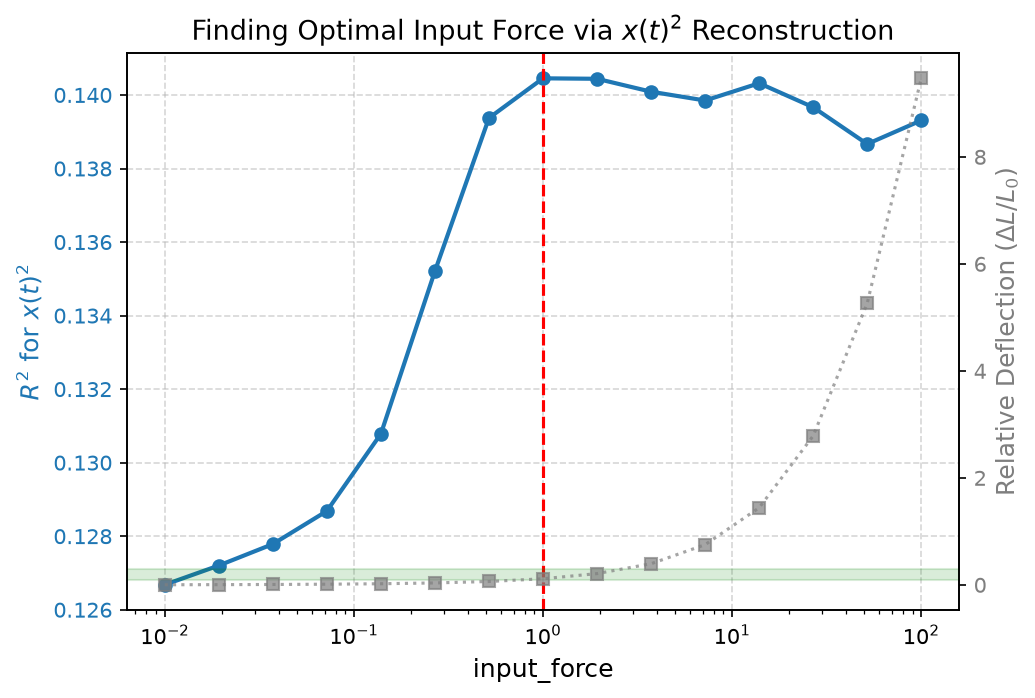

In [21]:
fig, ax1 = plt.subplots(figsize=(7, 4.5), dpi=150)

color = "tab:blue"
ax1.set_xlabel("input_force", fontsize=12)
ax1.set_xscale("log")
ax1.set_ylabel(r"$R^2$ for $x(t)^2$", color=color, fontsize=12)
ax1.plot(
    force_candidates,
    r2_scores,
    "-o",
    color=color,
    linewidth=2,
    label=r"$R^2$ for $x^2$",
)
ax1.axvline(
    optimal_force, color="red", linestyle="--", label=f"Optimal ({optimal_force:.2f})"
)
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

# Secondary axis: relative deflection magnitude
ax2 = ax1.twinx()
color = "tab:gray"
ax2.set_ylabel(r"Relative Deflection ($\Delta L / L_0$)", color=color, fontsize=12)
ax2.plot(
    force_candidates,
    mean_rel_displacements,
    ":s",
    color=color,
    alpha=0.7,
    label=r"Mean $\Delta x / L_0$",
)
ax2.axhspan(0.10, 0.30, color="green", alpha=0.15, label="Target Deflection (10-30%)")
ax2.tick_params(axis="y", labelcolor=color)

fig.tight_layout()
plt.title(r"Finding Optimal Input Force via $x(t)^2$ Reconstruction", fontsize=13)
plt.show()

In [25]:
tau_vals = np.arange(1, 6)
variance_names = [
    "k_wall_spread",
    "k_between_spread",
    "wall_rest_spread",
    "between_rest_spread",
]
sigma_vals = np.exp(np.linspace(0, 1, 10) * np.log(3)) - 1
num_trials = 1

tau_trials_nrmse = np.zeros((len(tau_vals), len(variance_names), len(sigma_vals)))
tau_trials_r2 = np.zeros((len(tau_vals), len(variance_names), len(sigma_vals)))

for tau_index, tau_val in enumerate(tau_vals):
    variance_trials_nrmse = np.zeros((len(variance_names), len(sigma_vals)))
    variance_trials_r2 = np.zeros((len(variance_names), len(sigma_vals)))

    for which_variance in range(len(variance_names)):
        sigma_vals = np.exp(np.linspace(0, 1, 10) * np.log(3)) - 1
        sigma_trials_nrmse_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))
        sigma_trials_r2_avg = np.zeros((len(sigma_vals), henon_scaled.shape[1]))

        for i, sigma in enumerate(sigma_vals):
            rng = np.random.default_rng(42)
            trial_rngs = rng.spawn(num_trials)
            rng_trials_nrmse_avg = np.zeros(henon_scaled.shape[1])
            rng_trials_r2_avg = np.zeros(henon_scaled.shape[1])

            for trial_rng in trial_rngs:
                steps_in_between = 30
                X = spring_trial(
                    trial_rng,
                    total_steps_after_chaos * steps_in_between,
                    input_force=3.5,
                    m_val=0.0001,
                    c_val=0.0447,
                    k_wall_val=5,
                    k_wall_spread=sigma if which_variance == 0 else 0,
                    k_between_val=4,
                    k_between_spread=sigma if which_variance == 1 else 0,
                    wall_rest_val=dist_y,
                    wall_rest_spread=sigma if which_variance == 2 else 0,
                    between_rest_val=dist_between,
                    between_rest_spread=sigma if which_variance == 3 else 0,
                    free_steps=steps_in_between
                )
                X_data = X[::steps_in_between]

                X_data = X[transient_steps_reservoir:-tau_val]
                Y_data = henon_scaled[transient_steps_reservoir + tau_val :]

                X_train, X_test = (
                    X_data[:-test_steps],
                    X_data[-test_steps:],
                )
                Y_train, Y_test = (
                    Y_data[:-test_steps],
                    Y_data[-test_steps:],
                )

                model = RidgeCV()
                model.fit(X_train, Y_train)
                Y_pred_scaled = model.predict(X_test)

                Y_pred = henon_scaler.inverse_transform(Y_pred_scaled)
                Y_test_org = henon_scaler.inverse_transform(Y_test)

                rmse_dims = root_mean_squared_error(
                    Y_test_org, Y_pred, multioutput="raw_values"
                )
                nrmse_dims = rmse_dims / np.std(Y_test_org, axis=0)

                r2_dims = r2_score(Y_test_org, Y_pred, multioutput="raw_values")

                rng_trials_nrmse_avg += nrmse_dims
                rng_trials_r2_avg += r2_dims

            rng_trials_nrmse_avg = rng_trials_nrmse_avg / num_trials
            rng_trials_r2_avg = rng_trials_r2_avg / num_trials

            sigma_trials_nrmse_avg[i] = rng_trials_nrmse_avg
            sigma_trials_r2_avg[i] = rng_trials_r2_avg

        sigma_trials_nrmse_avg_combined = sigma_trials_nrmse_avg[
            :, 0
        ]  # np.mean(sigma_trials_nrmse_avg, axis=1)
        sigma_trials_r2_avg_combined = sigma_trials_r2_avg[
            :, 0
        ]  # np.mean(sigma_trials_r2_avg, axis=1)

        variance_trials_nrmse[which_variance] = sigma_trials_nrmse_avg_combined
        variance_trials_r2[which_variance] = sigma_trials_r2_avg_combined

    tau_trials_nrmse[tau_index] = variance_trials_nrmse
    tau_trials_r2[tau_index] = variance_trials_r2

ValueError: Input X contains NaN.
_RidgeGCV does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [22]:
steps_in_between = 1000
X = spring_trial(
    trial_rng,
    total_steps_after_chaos * steps_in_between,
    input_force=3.5,
    m_val=0.0001,
    c_val=0.0447,
    k_wall_val=5,
    k_wall_spread=0,
    k_between_val=4,
    k_between_spread=0,
    wall_rest_val=dist_y,
    wall_rest_spread=0,
    between_rest_val=dist_between,
    between_rest_spread=0,
    free_steps=steps_in_between
)
X_data = X[::steps_in_between]

X_data = X[transient_steps_reservoir:-tau_val]
Y_data = henon_scaled[transient_steps_reservoir + tau_val :]

X_train, X_test = (
    X_data[:-test_steps],
    X_data[-test_steps:],
)
Y_train, Y_test = (
    Y_data[:-test_steps],
    Y_data[-test_steps:],
)

model = RidgeCV()
model.fit(X_train, Y_train)
Y_pred_scaled = model.predict(X_test)

Y_pred = henon_scaler.inverse_transform(Y_pred_scaled)
Y_test_org = henon_scaler.inverse_transform(Y_test)

rmse_dims = root_mean_squared_error(
    Y_test_org, Y_pred, multioutput="raw_values"
)
nrmse_dims = rmse_dims / np.std(Y_test_org, axis=0)

r2_dims = r2_score(Y_test_org, Y_pred, multioutput="raw_values")

: 

In [ ]:
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=[f"Spread: {name}" for name in variance_names],
    shared_xaxes=True,
    vertical_spacing=0.12,
    horizontal_spacing=0.08,
)

grid_positions = [(1, 1), (1, 2), (2, 1), (2, 2)]

for v_idx, (r, c) in enumerate(grid_positions):
    for tau_idx, tau_val in enumerate(tau_vals):
        fig.add_trace(
            go.Scatter(
                x=sigma_vals,
                y=tau_trials_nrmse[tau_idx, v_idx, :],
                mode="lines+markers",
                name=f"t+{tau_val}",
                line=dict(color=colors[tau_idx]),
                showlegend=(v_idx == 0),
            ),
            row=r,
            col=c,
        )

fig.update_xaxes(
    tickmode="array",
    tickvals=sigma_vals,
    ticktext=[f"{s:.2f}" for s in sigma_vals],
    tickangle=-45,
)
fig.update_xaxes(title_text="σ", row=2, col=1)
fig.update_xaxes(title_text="σ", row=2, col=2)
fig.update_yaxes(title_text="NRMSE", col=1)

fig.update_layout(
    height=800,
    width=1000,
    template="plotly_white",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.06,
        xanchor="center",
        x=0.5,
        title_text="Tau Horizon: ",
    ),
)

fig.show()